# Самостоятельная работа: контроль качества моделей
### Hold-out · KFold · StratifiedKFold · ShuffleSplit · cross-validation · кривые обучения
 
**Максимум:** 10 баллов  
**Данные:** `sklearn.datasets.load_breast_cancer`

В этой работе нужно **применить несколько инструментов scikit-learn, построить две диагностические кривые и объяснить результаты**. 

**Правила:**
1. Используйте `random_state=42` там, где он применим.
2. Обучающая и тестовая выборки создаются в готовой ячейке. **До задания 7 не используйте `X_test`** — он нужен для единственной финальной проверки.
3. В текстовых ответах достаточно 1–3 предложений.
4. Код пишите в ячейках с пометкой `TODO`; готовый код загрузки данных менять не нужно.

| № | Задание | Баллы |
|---|---|---:|
| 1 | Hold-out и базовая оценка | 1,0 |
| 2 | KFold, StratifiedKFold и StratifiedShuffleSplit | 2,0 |
| 3 | `cross_validate`: несколько метрик и переобучение | 1,5 |
| 4 | `cross_val_predict`: прогнозы out-of-fold | 1,0 |
| 5 | `learning_curve`: влияние размера выборки | 2,0 |
| 6 | `validation_curve`: подбор сложности дерева | 1,5 |
| 7 | Финальная проверка и вывод | 1,0 |
| | **Итого** | **10** |

## Подготовка: импорт и набор данных

Датасет содержит характеристики образцов опухолей. Цель — бинарная классификация: **0 — malignant**, **1 — benign**.

**Основная модель:** `DecisionTreeClassifier`. Ей не требуется масштабирование признаков, поэтому внимание можно сосредоточить на валидации.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold, StratifiedShuffleSplit,
    cross_val_score, cross_validate, cross_val_predict,
    learning_curve, validation_curve
)
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

X, y = load_breast_cancer(return_X_y=True, as_frame=True)
print('Объектов:', len(X), '| Признаков:', X.shape[1])
print('Доли классов:')
print(y.value_counts(normalize=True).sort_index().round(3).to_string())

# Отложенная тестовая выборка: не используйте её до задания 7.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
print(f'Обучающая выборка: {len(X_train)} | Отложенный тест: {len(X_test)}')

Объектов: 569 | Признаков: 30
Доли классов:
target
0    0.373
1    0.627
Обучающая выборка: 426 | Отложенный тест: 143


## 1. Hold-out: одна оценка качества · 1 балл

**Задание.** Сделайте **внутреннее** разбиение `X_train`, `y_train` на `X_subtrain` / `X_valid` в отношении 80% / 20% (с сохранением долей классов). Обучите дерево с `max_depth=4` на `X_subtrain` и вычислите `accuracy` **на обучающей части** и **на валидационной части**.

**Важно:** отложенный `X_test` здесь не трогаем.

**Вопрос:** почему точность на обучении обычно выше и почему качество по одному разбиению может быть нестабильным?

In [6]:
# TODO 1 (4 минуты)
X_subtrain, X_valid, y_subtrain, y_valid = train_test_split(X_train, y_train, train_size=0.8, stratify=y_train, random_state=42)
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X=X_subtrain, y=y_subtrain)
print('Train accuracy:', accuracy_score(y_subtrain, model.predict(X_subtrain)))
print('Validation accuracy:', accuracy_score(y_valid, model.predict(X_valid)))


Train accuracy: 0.9823529411764705
Validation accuracy: 0.9069767441860465


**Ответ к заданию 1:**

*Ваш ответ:* На обучении точность выше потому что модель уже видела эти данные, т.е. обучается на них и подстраивает свои веса под эти данные. На валидации обычно меньше потому что эти даннные она видит в первый раз и зависит от того как веса подобранные под обучающую выборку (какую зависимость она построила) подходят для валидационных данных. По одному разбиеннию будет нестабильна потому что на другом разбиении точность будет другая, модель обычно чувтсвительна к данным, особенно если выборка маленькая. на одном разбиении может быть переобучение на другом нет - данные всё для модели, меняются данные меняется результат

## 2. Разные схемы валидации · 2 балла

Создайте три объекта разбиения с `random_state=42`:
- `KFold(n_splits=5, shuffle=True)` — обычная K-fold CV;
- `StratifiedKFold(n_splits=5, shuffle=True)` — K-fold с сохранением долей классов;
- `StratifiedShuffleSplit(n_splits=5, test_size=0.2)` — пять случайных стратифицированных разбиений.

Для одного и того же `DecisionTreeClassifier(max_depth=4, random_state=42)` получите оценки через **`cross_val_score` на `X_train, y_train`**. Выведите по каждому методу 5 оценок, среднее и стандартное отклонение.

**Вопросы:** чем принципиально отличаются KFold и StratifiedKFold? Обязательно ли при StratifiedShuffleSplit каждый объект ровно один раз попадает в валидацию?

In [8]:
# TODO 2 (7 минут)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
sss = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=42)

splitters = {'KFold': kf, 'StratifiedKFold': skf, 'StratifiedShuffleSplit': sss}
for name, cv in splitters.items():
    scores = cross_val_score(estimator=DecisionTreeClassifier(max_depth=4, random_state=42), X=X_train, y=y_train, scoring='accuracy')
    print(name, 'оценки:', scores, 'среднее:', scores.mean(), 'std:', scores.std())


KFold оценки: [0.90697674 0.94117647 0.91764706 0.92941176 0.91764706] среднее: 0.9225718194254446 std: 0.01170154521440099
StratifiedKFold оценки: [0.90697674 0.94117647 0.91764706 0.92941176 0.91764706] среднее: 0.9225718194254446 std: 0.01170154521440099
StratifiedShuffleSplit оценки: [0.90697674 0.94117647 0.91764706 0.92941176 0.91764706] среднее: 0.9225718194254446 std: 0.01170154521440099


**Ответ к заданию 2:**

*Ваш ответ:* разбением одинакове, различается учетом пропорции классов у StratifiedKFold, чего нет у обычной KFold ( там как повезет ). Нет не обязательно, это случайное разбиение, есть вероятность что обьект может не попасть в валидацию.

## 3. `cross_validate`: несколько метрик и контроль переобучения · 1,5 балла

Сравните два дерева:
- **A**: `max_depth=4`;
- **B**: без ограничения глубины (`max_depth=None`).

Вызовите `cross_validate` с `cv=skf`, `return_train_score=True` и метриками `accuracy`, `balanced_accuracy`. Для каждой модели получите таблицу со средними:

`train_accuracy`, `test_accuracy`, `test_balanced_accuracy`.

**Вопрос:** у какой модели сильнее переобучение? По какому признаку это видно?

In [13]:
# TODO 3 (7 минут)
models = {'A': DecisionTreeClassifier(max_depth=4, random_state=42), 'B': DecisionTreeClassifier(max_depth=None, random_state=42)}
rows = []
for name, clf in models.items():
    result = cross_validate(clf, X_train, y_train, cv=skf, scoring={'accuracy': 'accuracy', 'balanced_accuracy': 'balanced_accuracy'}, return_train_score=True)
    rows.append({'модель': name, 'train_accuracy': result["train_accuracy"].mean(), 'test_accuracy': result["test_accuracy"].mean(),
                 'test_balanced_accuracy': result["test_balanced_accuracy"].mean()})
display(pd.DataFrame(rows).round(3))


,модель,train_accuracy,test_accuracy,test_balanced_accuracy
0,A,0.989,0.927,0.924
1,B,1.000,0.925,0.922


**Ответ к заданию 3:**

*Ваш ответ:* у B, по train_accuracy и разнице  train_accuracy - test_accuracy относительно этой же разницы в A модели.

## 4. `cross_val_predict`: прогноз для каждого объекта · 1 балл

С помощью `cross_val_predict` получите **out-of-fold** предсказания для всех объектов **`X_train`**, используя `skf` и модель `max_depth=4`. Постройте `ConfusionMatrixDisplay.from_predictions`.

**Вопрос:** чем эти предсказания отличаются от `model.predict(X_train)` после обучения дерева на всей обучающей выборке? Почему out-of-fold прогнозы не заменяют финальную проверку на `X_test`?

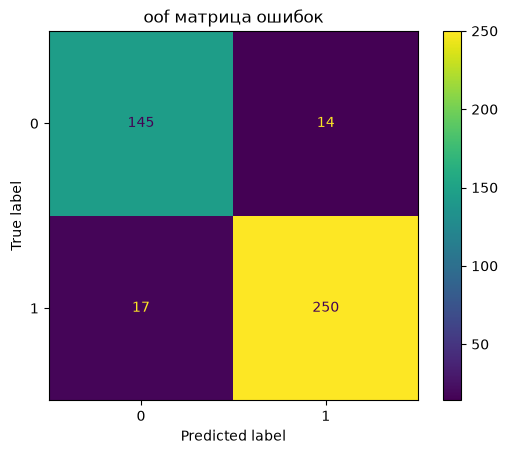

In [18]:
# TODO 4 (5 минут)
oof_pred = cross_val_predict(DecisionTreeClassifier(max_depth=4, random_state=42), X_train, y_train, cv=skf)
ConfusionMatrixDisplay.from_predictions(y_train, oof_pred)
plt.title('oof матрица ошибок')
plt.show()


**Ответ к заданию 4:**

*Ваш ответ:* model.predict(X_train) это предсказания на тех же данных, на которых модель училась: дерево их помнит, поэтому бесполезна как оценка качества. При проверке на x_test модель будет обучена на большем количестве данных чем oof, также мы на oof прогнозах мы проверяем модели и тюним параметры, отдельная x_test помогает проверить модель на данных которые вообще не использовались в процессе, что позволяет сделать оценку качества независимой (не подтасованной или оптимистичной)

## 5. `learning_curve`: помогает ли больше данных? · 2 балла

Для **дерева без ограничения глубины** постройте кривые обучения с помощью `learning_curve`:

- `train_sizes=np.linspace(0.15, 1.0, 6)`;
- `cv=skf`, `scoring='accuracy'`;
- `shuffle=True`, `random_state=42`.

По оси X — фактическое количество обучающих объектов, по Y — **средняя** accuracy на обучающих и валидационных фолдах. Две линии на одном графике: *Train* и *CV*.

**Вопросы:** как выглядят признаки переобучения на графике? Похоже ли, что простое увеличение числа объектов полностью устранит проблему?

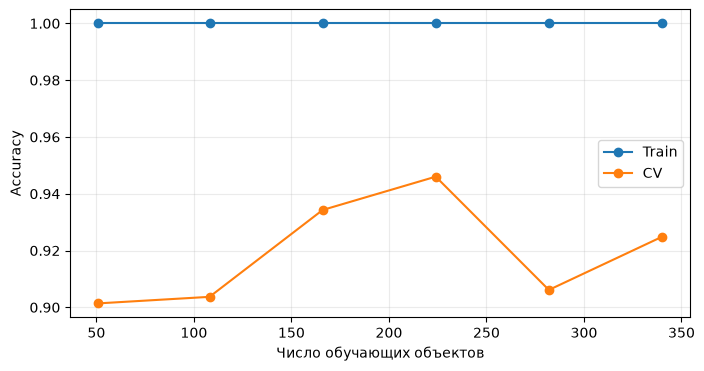

In [19]:
# TODO 5 (8 минут)
sizes, train_scores, val_scores = learning_curve(DecisionTreeClassifier(max_depth=None, random_state=42), X_train, y_train, train_sizes=np.linspace(0.15, 1.0, 6),
    cv=skf, scoring='accuracy', shuffle=True, random_state=42
)

plt.figure(figsize=(8, 4))
plt.plot(sizes, train_scores.mean(axis=1), 'o-', label='Train')
plt.plot(sizes, val_scores.mean(axis=1), 'o-', label='CV')
plt.xlabel('Число обучающих объектов')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.25)
plt.show()


**Ответ к заданию 5:**

*Ваш ответ:* линия треин всегда равна 1, и не похожа на cv. на графике видно что хоть валидация и растет но выходит на плато. Увеличение данных не полносью проблему не устранят.

## 6. `validation_curve`: какая глубина дерева лучше? · 1,5 балла

С помощью `validation_curve` оцените значения `max_depth` от **1 до 15 включительно**. Используйте `skf`, метрику `accuracy` и `DecisionTreeClassifier(random_state=42)`.

Постройте две кривые на одном графике: средняя `Train accuracy` и средняя `CV accuracy` в зависимости от `max_depth`. Автоматически определите `best_depth` — глубину с **максимальной средней CV accuracy** (при равенстве выберите меньшую глубину).

**Вопрос:** как по графику распознать недообучение и переобучение?

Оптимальная глубина по CV: 3


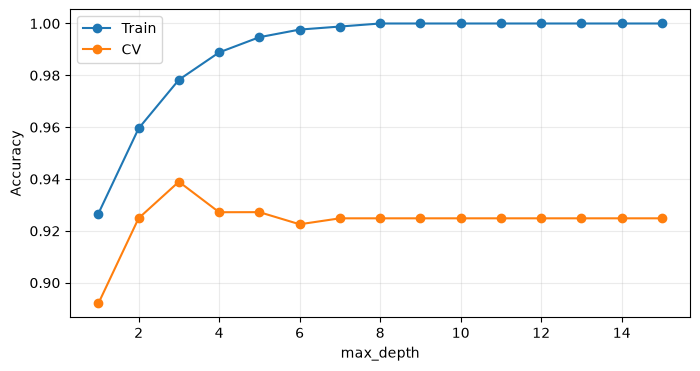

In [24]:
# TODO 6 (7 минут)
depths = np.arange(1, 16)
train_v, val_v = validation_curve(
    DecisionTreeClassifier(random_state=42), X_train, y_train, param_name='max_depth', param_range=depths,
    cv=skf, scoring='accuracy'
)
# Постройте график средних train_v и val_v.
best_depth = depths[np.argmax(val_mean)]
print('Оптимальная глубина по CV:', best_depth)

plt.figure(figsize=(8, 4))
plt.plot(depths, train_v.mean(axis=1), 'o-', label='Train')
plt.plot(depths, val_v.mean(axis=1), 'o-', label='CV')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.25)
plt.show()


**Ответ к заданию 6:**

*Ваш ответ:* недообучение на графике можно увидеть по паралельно идущим train и cv, и обычно низкие метрики что на train, что на cv. Переобучение когда точность на валидации падает а train все еще либо поднимается либо уже стоит в 1.0

## 7. Финальная проверка  · 1 балл

Теперь, когда глубина выбрана по CV, обучите **одно** дерево с `max_depth=best_depth` на **всей** `X_train` и **один раз** оцените `accuracy` на `X_test`.

**Короткий вывод (2–3 предложения):** чем отличается CV-оценка от тестовой? Зачем нужны *обе* кривые — `learning_curve` и `validation_curve`?

In [25]:
# TODO 7 (2 минуты)
final_model = DecisionTreeClassifier(random_state=42, max_depth=best_depth)
final_model.fit(X_train, y_train)
final_test_accuracy = accuracy_score(y_test, final_model.predict(X_test))
print(final_test_accuracy)


0.9440559440559441


**Итоговый вывод:**

*Ваш ответ:* на первый вопрос отвечал: "При проверке на x_test модель будет обучена на большем количестве данных чем oof, также мы на oof прогнозах мы проверяем модели и тюним параметры, отдельная x_test помогает проверить модель на данных которые вообще не использовались в процессе, что позволяет сделать оценку качества независимой (не подтасованной или оптимистичной)". lc и vc дают понять то что мы не можем понять просто получив метрику, а именно в случае lc: досаточно ли данных, в vc: какие параметры взять лучше чтобы метрика была выше

---
### Дополнительное задание (не входит в 40 минут и в 10 баллов)

Замените `skf` на `RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)` в задании 2. Сравните число оценок, их среднее и стандартное отклонение. Объясните, почему повторение CV даёт больше информации об изменчивости качества, но **не создаёт новые независимые данные**.